In [71]:

import torch
import torchvision
from torchvision import datasets

root = "/content/pet_dataset"

train_data = datasets.OxfordIIITPet(
    root=root,
    split="trainval",
    target_types="category",
    download=True
)

test_data = datasets.OxfordIIITPet(
    root=root,
    split="test",
    target_types="category",
    download=True
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))
print("Number of classes:", len(train_data.classes))


Training images: 3680
Testing images: 3669
Number of classes: 37


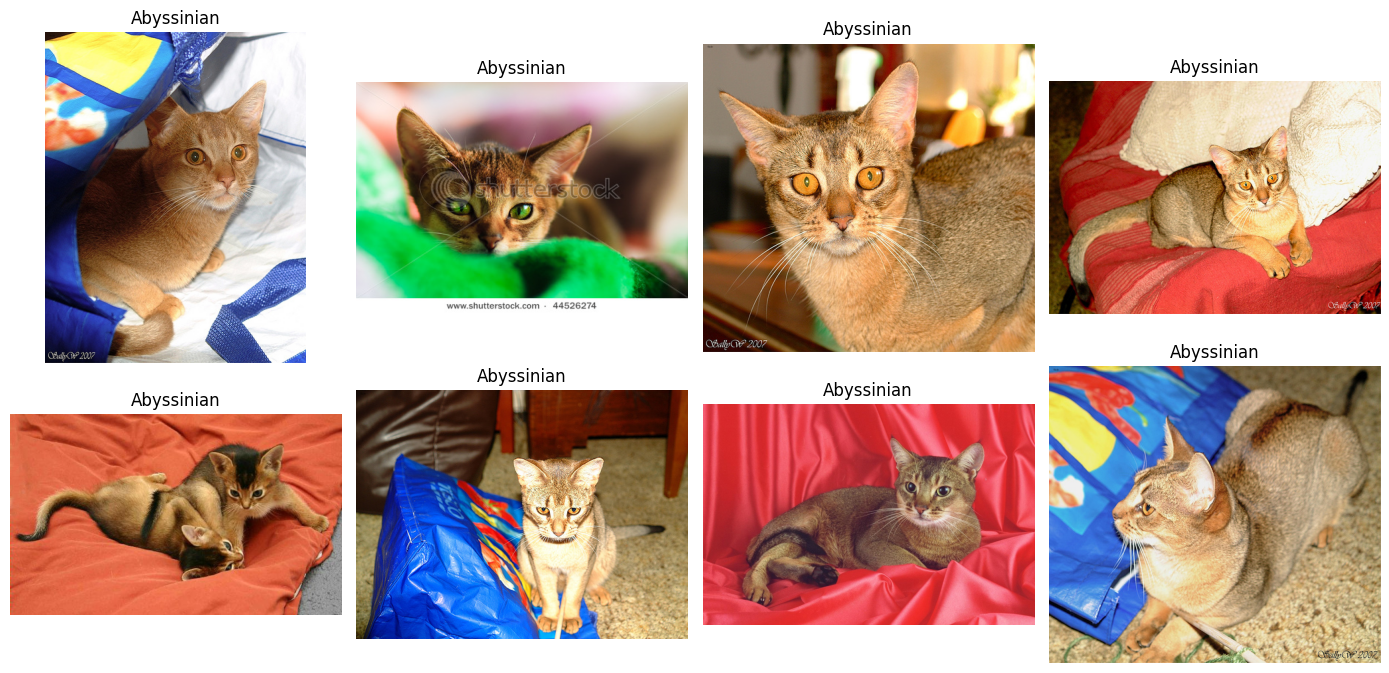

In [72]:

import matplotlib.pyplot as plt

# Display 8 animal images
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]

    ax.imshow(image)
    ax.set_title(train_data.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [73]:
print("Number of classes:", len(train_data.classes))

for i, name in enumerate(train_data.classes):
  print(i, ":", name)

Number of classes: 37
0 : Abyssinian
1 : American Bulldog
2 : American Pit Bull Terrier
3 : Basset Hound
4 : Beagle
5 : Bengal
6 : Birman
7 : Bombay
8 : Boxer
9 : British Shorthair
10 : Chihuahua
11 : Egyptian Mau
12 : English Cocker Spaniel
13 : English Setter
14 : German Shorthaired
15 : Great Pyrenees
16 : Havanese
17 : Japanese Chin
18 : Keeshond
19 : Leonberger
20 : Maine Coon
21 : Miniature Pinscher
22 : Newfoundland
23 : Persian
24 : Pomeranian
25 : Pug
26 : Ragdoll
27 : Russian Blue
28 : Saint Bernard
29 : Samoyed
30 : Scottish Terrier
31 : Shiba Inu
32 : Siamese
33 : Sphynx
34 : Staffordshire Bull Terrier
35 : Wheaten Terrier
36 : Yorkshire Terrier


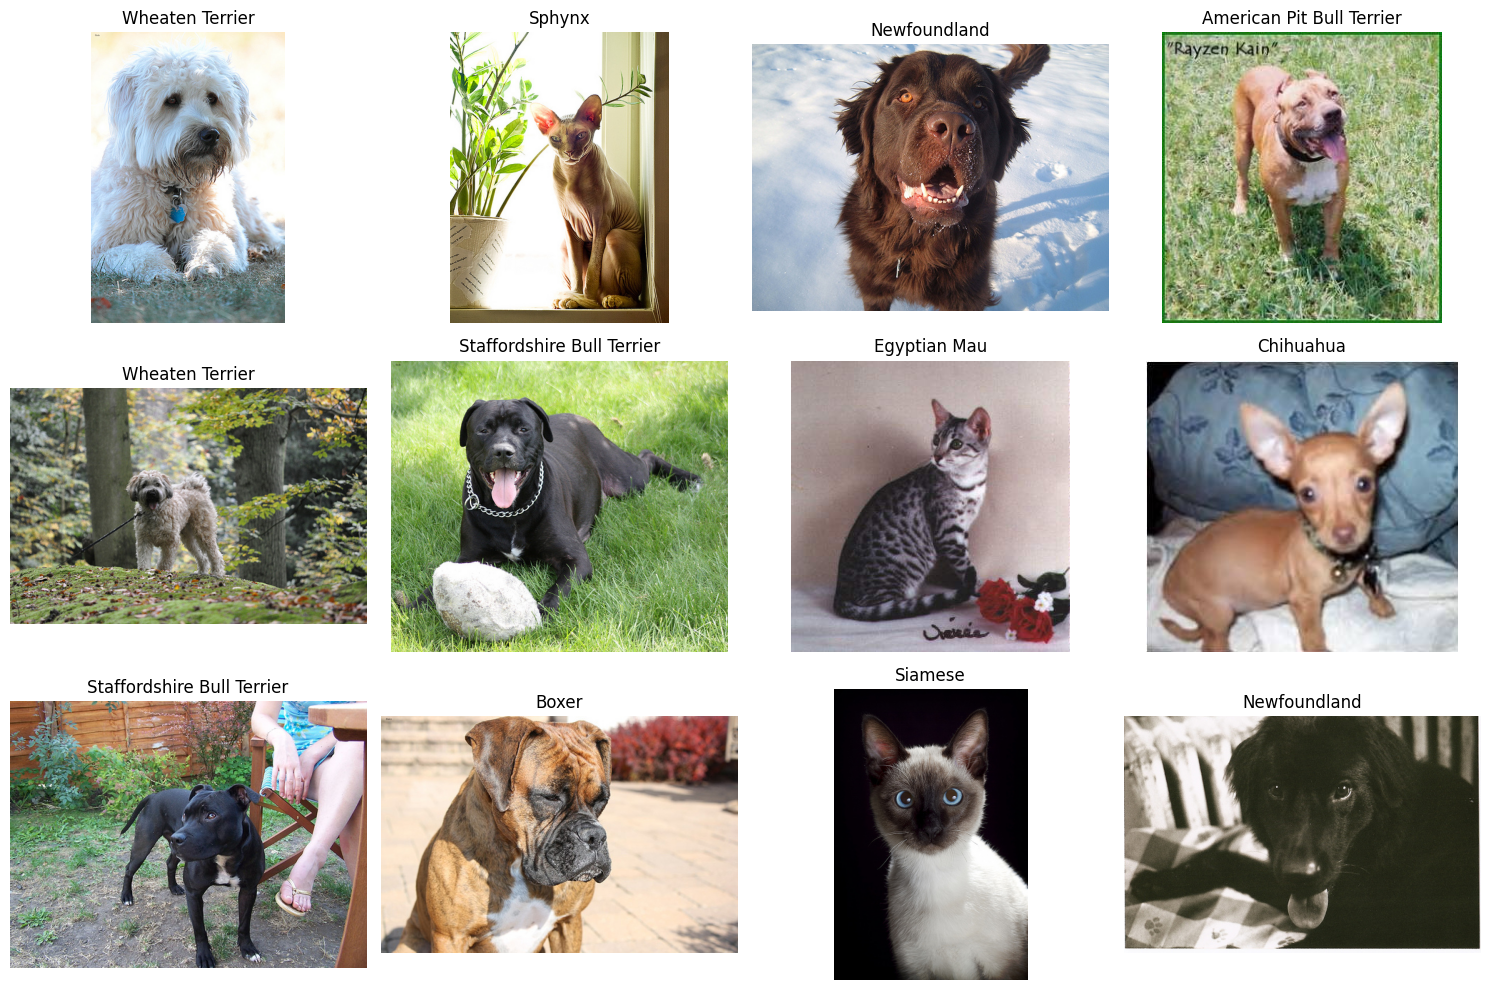

In [74]:
import random
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3,4, figsize=(15, 10))

indices = random.sample(range(len(train_data)), 12)

for i, ax in zip(indices, axes.flat):
  image, label = train_data[i]

  ax.imshow(image)
  ax.set_title(train_data.classes[label])
  ax.axis("off")

plt.tight_layout()
plt.show()

In [75]:
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

print("Preprocessing libraries ready!")

Preprocessing libraries ready!


In [76]:
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Transforms created succesfully!")

Transforms created succesfully!


In [77]:

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Test transform ready!")


Test transform ready!


In [78]:

train_aug = datasets.OxfordIIITPet(
    root=root,
    split="trainval",
    target_types="category",
    transform=train_transform,
    download=False
)

train_eval = datasets.OxfordIIITPet(
    root=root,
    split="trainval",
    target_types="category",
    transform=test_transform,
    download=False
)

test_dataset = datasets.OxfordIIITPet(
    root=root,
    split="test",
    target_types="category",
    transform=test_transform,
    download=False
)

print("Datasets ready!")


Datasets ready!


In [79]:
from torch.utils.data import random_split

generator = torch.Generator().manual_seed(42)

train_indices, val_indices = random_split(
   range(len(train_aug)),
    [2944, 736],
    generator=generator
)

train_dataset = Subset(train_aug, train_indices.indices)
val_dataset = Subset(train_eval, val_indices.indices)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))



Training: 2944
Validation: 736
Testing: 3669


In [80]:
from torch.utils.data import dataloader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("Dataloaders created succesfully!")

Dataloaders created succesfully!


In [81]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Numder of classes:", len(train_data.classes))

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Numder of classes: 37


In [82]:
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score

train_labels = [
    train_data[i][1] for i in train_indices.indices
]

class_counts = Counter(train_labels)

majority_class = class_counts.most_common(1)[0][0]

print("Majority class:", train_data.classes[majority_class])
print("Number of samples:", class_counts[majority_class])

Majority class: Basset Hound
Number of samples: 87


In [83]:
true_labels = [
    test_data[i][1] for i in range(len(test_data))
]

predictions = [majority_class] * len(true_labels)

accuracy = accuracy_score(true_labels, predictions)

macro_f1 = f1_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

print("BASELINE RESULTS")
print("_____________")
print("Accuracy:", round(accuracy, 4))
print("Macro F1:", round(macro_f1, 4))


BASELINE RESULTS
_____________
Accuracy: 0.0273
Macro F1: 0.0014


In [84]:

import torch
import torch.nn as nn

class AnimalCNN(nn.Module):
    def __init__(self, num_classes=37):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


model = AnimalCNN(num_classes=37)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print(model)
print("Device:", device)


AnimalCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2)

In [85]:
images, labels = next(iter(train_loader))

images = images.to(device)

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Model test succesful!")

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 37])
Model test succesful!


In [86]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Epochs:", epochs)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Epochs: 10


In [87]:

def train_model(model, train_loader, val_loader,
                criterion, optimizer, epochs, device):

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        # Training
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / total
        epoch_accuracy = correct / total

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        # Validation
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)

                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / val_total
        val_epoch_accuracy = val_correct / val_total

        val_losses.append(val_epoch_loss)
        val_accuracies.append(val_epoch_accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {epoch_loss:.4f} "
            f"Train Acc: {epoch_accuracy:.4f} "
            f"Val Loss: {val_epoch_loss:.4f} "
            f"Val Acc: {val_epoch_accuracy:.4f}"
        )

    return train_losses, val_losses, train_accuracies, val_accuracies


In [88]:
train_losses, val_losses, train_acc, val_acc = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs,
    device
)

print("Training completed!")

Epoch [1/10] Train Loss: 3.5969 Train Acc: 0.0465 Val Loss: 3.5094 Val Acc: 0.0503
Epoch [2/10] Train Loss: 3.4960 Train Acc: 0.0676 Val Loss: 3.4397 Val Acc: 0.0938
Epoch [3/10] Train Loss: 3.4522 Train Acc: 0.0757 Val Loss: 3.4191 Val Acc: 0.0897
Epoch [4/10] Train Loss: 3.4037 Train Acc: 0.0856 Val Loss: 3.3948 Val Acc: 0.0924
Epoch [5/10] Train Loss: 3.3754 Train Acc: 0.1009 Val Loss: 3.3744 Val Acc: 0.1114
Epoch [6/10] Train Loss: 3.3447 Train Acc: 0.1022 Val Loss: 3.3936 Val Acc: 0.0924
Epoch [7/10] Train Loss: 3.3238 Train Acc: 0.0924 Val Loss: 3.3416 Val Acc: 0.0938
Epoch [8/10] Train Loss: 3.2856 Train Acc: 0.1141 Val Loss: 3.3051 Val Acc: 0.1236
Epoch [9/10] Train Loss: 3.2658 Train Acc: 0.1189 Val Loss: 3.2570 Val Acc: 0.1345
Epoch [10/10] Train Loss: 3.2458 Train Acc: 0.1182 Val Loss: 3.2634 Val Acc: 0.1114
Training completed!


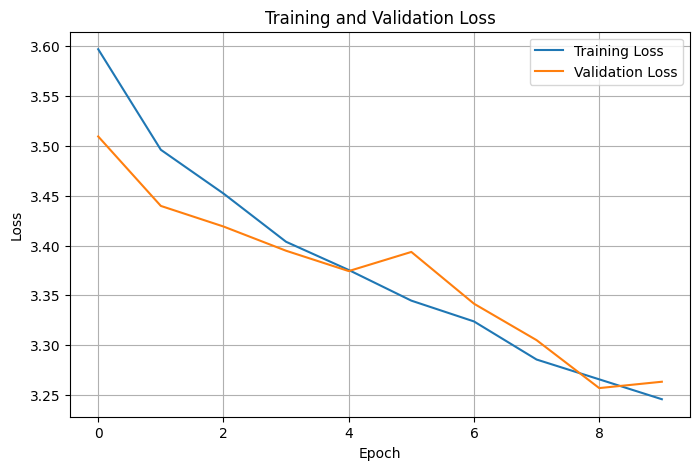

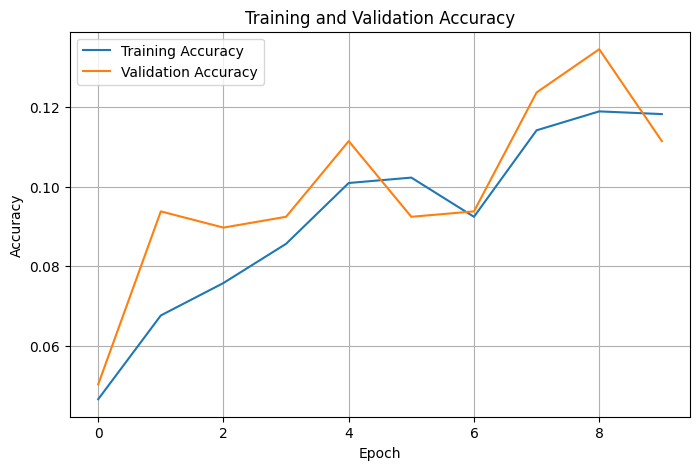

In [89]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(train_acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()

plt.show()


In [90]:

from sklearn.metrics import accuracy_score, f1_score
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

test_accuracy = accuracy_score(
    all_labels, all_predictions
)

test_macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print("CNN MODEL A - TEST RESULTS")
print("---------------------------")
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro F1:", round(test_macro_f1, 4))


CNN MODEL A - TEST RESULTS
---------------------------
Test Accuracy: 0.0869
Test Macro F1: 0.0734


In [91]:
print("BASELINE vs CNN MODEL A")
print("-----------------------")

print("baseline Accuracy:0.0273")
print("CNN Accuracy:", round(test_accuracy, 4))

print("baseline Macro F1:0.0014")
print("CNN Macro F1:", round(test_macro_f1, 4))



BASELINE vs CNN MODEL A
-----------------------
baseline Accuracy:0.0273
CNN Accuracy: 0.0869
baseline Macro F1:0.0014
CNN Macro F1: 0.0734


In [92]:

from sklearn.metrics import accuracy_score, f1_score
import torch

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(
    all_labels, all_predictions
)

test_macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro F1:", round(test_macro_f1, 4))


Test Accuracy: 0.0869
Test Macro F1: 0.0734


In [93]:

import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")


PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [94]:

import os
from torchvision import datasets

root = "/content/pet_dataset"

print("Dataset folder exists:", os.path.exists(root))

if os.path.exists(root):
    train_data = datasets.OxfordIIITPet(
        root=root,
        split="trainval",
        target_types="category",
        download=False
    )

    test_data = datasets.OxfordIIITPet(
        root=root,
        split="test",
        target_types="category",
        download=False
    )

    print("Training images:", len(train_data))
    print("Testing images:", len(test_data))
    print("Classes:", len(train_data.classes))


Dataset folder exists: True
Training images: 3680
Testing images: 3669
Classes: 37


In [95]:

import os
from torchvision import datasets

root = "/content/drive/MyDrive/pet_dataset"

train_data = datasets.OxfordIIITPet(
    root=root,
    split="trainval",
    target_types="category",
    download=True
)

test_data = datasets.OxfordIIITPet(
    root=root,
    split="test",
    target_types="category",
    download=True
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))
print("Classes:", len(train_data.classes))
print("Dataset saved in Google Drive!")


Training images: 3680
Testing images: 3669
Classes: 37
Dataset saved in Google Drive!


In [96]:

from torchvision import transforms
from torch.utils.data import DataLoader, Subset, random_split

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and testing transformations
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transforms restored successfully!")


Transforms restored successfully!


In [97]:

train_aug = datasets.OxfordIIITPet(
    root=root,
    split="trainval",
    target_types="category",
    transform=train_transform,
    download=False
)

train_eval = datasets.OxfordIIITPet(
    root=root,
    split="trainval",
    target_types="category",
    transform=test_transform,
    download=False
)

test_dataset = datasets.OxfordIIITPet(
    root=root,
    split="test",
    target_types="category",
    transform=test_transform,
    download=False
)

print("Datasets restored successfully!")


Datasets restored successfully!


In [98]:
import torch
from torch.utils.data import random_split, Subset

generator = torch.Generator().manual_seed(42)

train_indices, val_indices = random_split(
    range(len(train_aug)),
    [2944, 736],
    generator=generator
)

train_dataset = Subset(train_aug, train_indices.indices)
val_dataset = Subset(train_eval, val_indices.indices)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 2944
Validation: 736
Testing: 3669


In [99]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("DataLoaders restored successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders restored successfully!
Training batches: 92
Validation batches: 23
Testing batches: 115


In [100]:
import torch
import torch.nn as nn

class AnimalCNN(nn.Module):
    def __init__(self, num_classes=37):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AnimalCNN(num_classes=37).to(device)

print("Model restored successfully!")
print("Device:", device)

Model restored successfully!
Device: cuda


In [101]:
import torch.optim as optim
import torch.nn as nn
import os

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 10

checkpoint_path = "/content/drive/MyDrive/AnimalCNN_checkpoint.pth"

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

print("Training setup completed!")
print("Epochs:", epochs)
print("Learning rate:", 0.001)
print("Checkpoint:", checkpoint_path)

Training setup completed!
Epochs: 10
Learning rate: 0.001
Checkpoint: /content/drive/MyDrive/AnimalCNN_checkpoint.pth


In [102]:
def train_model(model, train_loader, val_loader, criterion,
                optimizer, epochs, device, checkpoint_path):

    for epoch in range(epochs):
        # Training
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / total
        train_acc = correct / total

        # Validation
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)

                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

        # Save checkpoint to Google Drive
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_losses": train_losses,
            "val_losses": val_losses,
            "train_accuracies": train_accuracies,
            "val_accuracies": val_accuracies
        }, checkpoint_path)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} "
            f"Train Acc: {train_acc:.4f} "
            f"Val Loss: {val_loss:.4f} "
            f"Val Acc: {val_acc:.4f}"
        )

    print("Training completed!")

In [103]:
print(train_model)

<function train_model at 0x7a8f5c3891c0>


In [104]:
train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=epochs,
    device=device,
    checkpoint_path=checkpoint_path
)

Epoch [1/10] Train Loss: 3.5856 Train Acc: 0.0523 Val Loss: 3.4924 Val Acc: 0.0761
Epoch [2/10] Train Loss: 3.5001 Train Acc: 0.0560 Val Loss: 3.4662 Val Acc: 0.0802
Epoch [3/10] Train Loss: 3.4610 Train Acc: 0.0744 Val Loss: 3.4381 Val Acc: 0.0720
Epoch [4/10] Train Loss: 3.4166 Train Acc: 0.0798 Val Loss: 3.4072 Val Acc: 0.0870
Epoch [5/10] Train Loss: 3.3945 Train Acc: 0.0856 Val Loss: 3.3841 Val Acc: 0.0910
Epoch [6/10] Train Loss: 3.3674 Train Acc: 0.0954 Val Loss: 3.3917 Val Acc: 0.0924
Epoch [7/10] Train Loss: 3.3278 Train Acc: 0.0995 Val Loss: 3.3309 Val Acc: 0.1060
Epoch [8/10] Train Loss: 3.3220 Train Acc: 0.1043 Val Loss: 3.3132 Val Acc: 0.0992
Epoch [9/10] Train Loss: 3.2849 Train Acc: 0.1073 Val Loss: 3.3417 Val Acc: 0.1046
Epoch [10/10] Train Loss: 3.2618 Train Acc: 0.1135 Val Loss: 3.2525 Val Acc: 0.1236
Training completed!


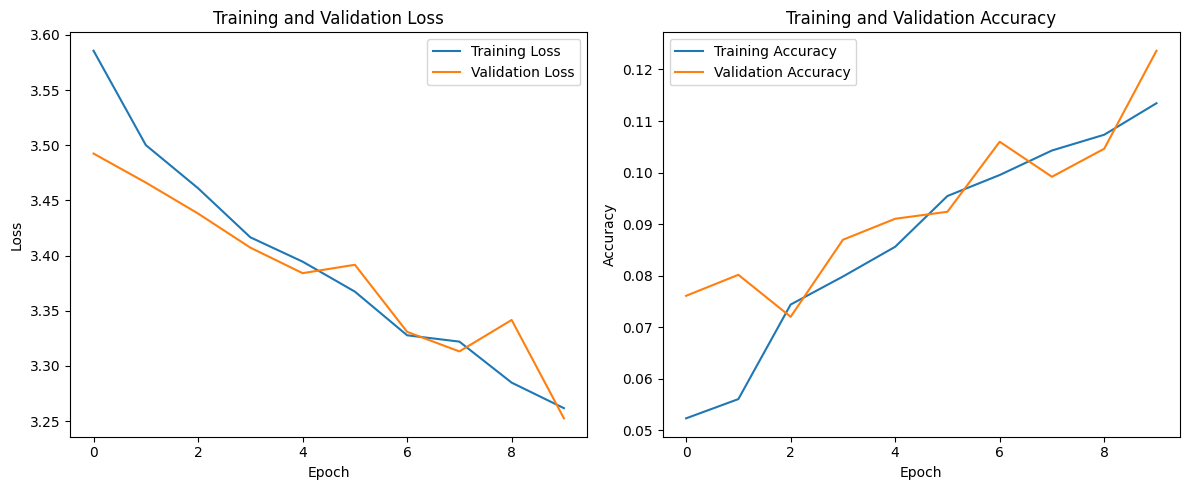

In [105]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [106]:
from sklearn.metrics import accuracy_score, f1_score

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)
test_f1 = f1_score(all_labels, all_predictions, average="macro")

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro F1:", round(test_f1, 4))

Test Accuracy: 0.0932
Test Macro F1: 0.0744


In [107]:
import json

results = {
    "model": "AnimalCNN",
    "epochs": 10,
    "learning_rate": 0.001,
    "validation_accuracy": val_accuracies[-1],
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_f1
}

results_path = "/content/drive/MyDrive/ModelA_results.json"

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("Model A results saved successfully!")

Model A results saved successfully!


In [108]:
from torch.utils.data import random_split, Subset

train_size = int(0.8 * len(train_aug))
val_size = len(train_aug) - train_size

train_indices, val_indices = random_split(
    range(len(train_aug)),
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_dataset = Subset(train_aug, train_indices)
val_dataset = Subset(train_eval, val_indices)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 2944
Validation: 736
Testing: 3669


In [109]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 92
Validation batches: 23
Test batches: 115


In [111]:
import torch.nn as nn

class AnimalCNN(nn.Module):
    def __init__(self, num_classes=37):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x

print("AnimalCNN model created successfully!")

AnimalCNN model created successfully!


In [112]:
model = AnimalCNN(num_classes=37).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model:", device)
print("Loss function", criterion)
print("Optimizer", optimizer)

Model: cuda
Loss function CrossEntropyLoss()
Optimizer Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [113]:
import time

epochs = 10

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {train_loss:.4f} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Val Acc: {val_acc:.4f}")

training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

Epoch 1/10 | Train Loss: 3.6071 | Train Acc: 0.0397 | Val Loss: 3.5188 | Val Acc: 0.0503
Epoch 2/10 | Train Loss: 3.5138 | Train Acc: 0.0594 | Val Loss: 3.4636 | Val Acc: 0.0707
Epoch 3/10 | Train Loss: 3.4633 | Train Acc: 0.0713 | Val Loss: 3.4471 | Val Acc: 0.0761
Epoch 4/10 | Train Loss: 3.4369 | Train Acc: 0.0825 | Val Loss: 3.4001 | Val Acc: 0.0992
Epoch 5/10 | Train Loss: 3.3994 | Train Acc: 0.0819 | Val Loss: 3.3859 | Val Acc: 0.0856
Epoch 6/10 | Train Loss: 3.3795 | Train Acc: 0.0931 | Val Loss: 3.3723 | Val Acc: 0.1114
Epoch 7/10 | Train Loss: 3.3600 | Train Acc: 0.0948 | Val Loss: 3.3422 | Val Acc: 0.1019
Epoch 8/10 | Train Loss: 3.3346 | Train Acc: 0.0934 | Val Loss: 3.3672 | Val Acc: 0.1005
Epoch 9/10 | Train Loss: 3.2966 | Train Acc: 0.1107 | Val Loss: 3.3630 | Val Acc: 0.0924
Epoch 10/10 | Train Loss: 3.2788 | Train Acc: 0.1138 | Val Loss: 3.2991 | Val Acc: 0.1141
Training time: 116.23 seconds


In [115]:
from sklearn.metrics import accuracy_score, f1_score

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1 )

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)
test_f1 = f1_score(all_labels, all_predictions, average="macro")

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_f1:.4f}")

Test Accuracy: 0.0834
Test Macro F1: 0.0645


In [117]:
import json 

result = {
    "model": "AnimalCNN",
    "epoch": 10,
    "learning_rate": 0.001,
    "validatian_accuracy": val_accuracies[-1],
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_f1,
    "training_time_seconds": training_time
}

with open("/kaggle/working/ModelA_results.json", "w") as f:
    json.dump(results, f, indent=4)

torch.save(
    model.state_dict(),
    "/kaggle/working/AnimalCNN_model.pth"
)

print("Model A results and checkpoint saved!")

Model A results and checkpoint saved!


In [118]:
model_b = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

model_b.fc = nn.Linear(
    model_b.fc.in_features,
    37
)

model_b = model_b.to(device)

print("ResNet18 model created successfully!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 182MB/s] 


ResNet18 model created successfully!


In [120]:
criterion_b = nn.CrossEntropyLoss()

optimizer_b = torch.optim.Adam(
    model_b.parameters(),
    lr=0.0001
)

print("Model B:", device )
print("Loss function:", criterion_b)
print("Optimizer:", optimizer_b)

Model B: cuda
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [121]:
epochs = 10

train_losses_b = []
val_losses_b = []
train_accuracies_b = []
val_accuracies_b = []

start_time_b = time.time()

for epoch in range(epochs):
    model_b.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_b.zero_grad()
        outputs = model_b(images)
        loss = criterion_b(outputs, labels)
        loss.backward()
        optimizer_b.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    model_b.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model_b(images)
            loss = criterion_b(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    train_losses_b.append(train_loss)
    val_losses_b.append(val_loss)
    train_accuracies_b.append(train_acc)
    val_accuracies_b.append(val_acc)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {train_loss:.4f} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Val Acc: {val_acc:.4f}")

training_time_b = time.time() - start_time_b
print(f"Training time: {training_time_b:.2f} seconds")

Epoch 1/10 | Train Loss: 1.8543 | Train Acc: 0.6016 | Val Loss: 0.8261 | Val Acc: 0.8451
Epoch 2/10 | Train Loss: 0.5866 | Train Acc: 0.8984 | Val Loss: 0.5634 | Val Acc: 0.8478
Epoch 3/10 | Train Loss: 0.3118 | Train Acc: 0.9504 | Val Loss: 0.4757 | Val Acc: 0.8668
Epoch 4/10 | Train Loss: 0.1750 | Train Acc: 0.9766 | Val Loss: 0.4246 | Val Acc: 0.8845
Epoch 5/10 | Train Loss: 0.1098 | Train Acc: 0.9912 | Val Loss: 0.4611 | Val Acc: 0.8573
Epoch 6/10 | Train Loss: 0.0700 | Train Acc: 0.9942 | Val Loss: 0.3932 | Val Acc: 0.8845
Epoch 7/10 | Train Loss: 0.0490 | Train Acc: 0.9956 | Val Loss: 0.3520 | Val Acc: 0.8859
Epoch 8/10 | Train Loss: 0.0340 | Train Acc: 0.9990 | Val Loss: 0.3509 | Val Acc: 0.8954
Epoch 9/10 | Train Loss: 0.0248 | Train Acc: 0.9983 | Val Loss: 0.3667 | Val Acc: 0.8886
Epoch 10/10 | Train Loss: 0.0231 | Train Acc: 0.9986 | Val Loss: 0.3676 | Val Acc: 0.8872
Training time: 131.04 seconds


In [122]:
model_b.eval()

all_predictions_b = []
all_labels_b = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_b(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions_b.extend(predictions.cpu().numpy())
        all_labels_b.extend(labels.numpy())

test_accuracy_b = accuracy_score(
    all_labels_b, all_predictions_b
)

test_f1_b = f1_score(
    all_labels_b, all_predictions_b,
    average="macro"
)

print(f"Test Accuracy: {test_accuracy_b:.4f}")
print(f"Test Macro F1: {test_f1_b:.4f}")

Test Accuracy: 0.8700
Test Macro F1: 0.8686


In [123]:
results_b = {
    "model": "ResNet18",
    "epochs": 10,
    "learning_rate": 0.0001,
    "validation_accuracy": max(val_accuracies_b),
    "test_accuracy": test_accuracy_b,
    "test_macro_f1": test_f1_b,
    "training_time_seconds": training_time_b
}

with open("/kaggle/working/ModelB_results.json", "w") as f:
    json.dump(results_b, f, indent=4)

torch.save(
    model_b.state_dict(),
    "/kaggle/working/ResNet18_model.pth"
)

print("Model B results and checkpoint saved!")

Model B results and checkpoint saved!


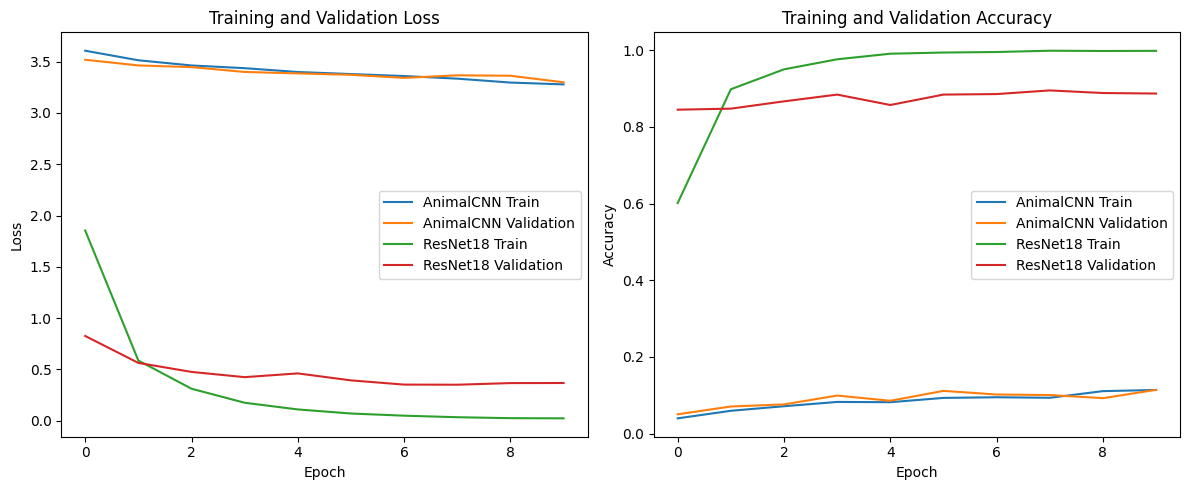

In [124]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="AnimalCNN Train")
plt.plot(val_losses, label="AnimalCNN Validation")
plt.plot(train_losses_b, label="ResNet18 Train")
plt.plot(val_losses_b, label="ResNet18 Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="AnimalCNN Train")
plt.plot(val_accuracies, label="AnimalCNN Validation")
plt.plot(train_accuracies_b, label="ResNet18 Train")
plt.plot(val_accuracies_b, label="ResNet18 Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [125]:
model_b_lr001 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

model_b_lr001.fc = nn.Linear(
    model_b_lr001.fc.in_features,
    37
)

model_b_lr001 = model_b_lr001.to(device)

criterion_lr001 = nn.CrossEntropyLoss()

optimizer_lr001 = torch.optim.Adam(
    model_b_lr001.parameters(),
    lr=0.001
)

print("Experiment 1 model created!")
print("Learning rate:", 0.001)

Experiment 1 model created!
Learning rate: 0.001


In [126]:
epochs = 10

train_losses_lr001 = []
val_losses_lr001 = []
train_accuracies_lr001 = []
val_accuracies_lr001 = []

start_time_lr001 = time.time()

for epoch in range(epochs):
    model_b_lr001.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_lr001.zero_grad()
        outputs = model_b_lr001(images)
        loss = criterion_lr001(outputs, labels)
        loss.backward()
        optimizer_lr001.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    model_b_lr001.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model_b_lr001(images)
            loss = criterion_lr001(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    train_losses_lr001.append(train_loss)
    val_losses_lr001.append(val_loss)
    train_accuracies_lr001.append(train_acc)
    val_accuracies_lr001.append(val_acc)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Acc: {val_acc:.4f}")

training_time_lr001 = time.time() - start_time_lr001

print("Training time:", round(training_time_lr001, 2), "seconds")

Epoch 1/10 | Train Acc: 0.5204 | Val Acc: 0.3981
Epoch 2/10 | Train Acc: 0.6882 | Val Acc: 0.4932
Epoch 3/10 | Train Acc: 0.7476 | Val Acc: 0.5951
Epoch 4/10 | Train Acc: 0.8006 | Val Acc: 0.6277
Epoch 5/10 | Train Acc: 0.8387 | Val Acc: 0.6277
Epoch 6/10 | Train Acc: 0.8665 | Val Acc: 0.6304
Epoch 7/10 | Train Acc: 0.8886 | Val Acc: 0.6970
Epoch 8/10 | Train Acc: 0.9263 | Val Acc: 0.7079
Epoch 9/10 | Train Acc: 0.9317 | Val Acc: 0.6957
Epoch 10/10 | Train Acc: 0.9399 | Val Acc: 0.6712
Training time: 130.87 seconds


In [127]:
results_lr001 = {
    "model": "ResNet18",
    "learning_rate": 0.001,
    "epochs": 10,
    "best_val_accuracy": max(val_accuracies_lr001),
    "final_val_accuracy": val_accuracies_lr001[-1],
    "training_time": training_time_lr001
}

with open("/kaggle/working/Experiment1_LR001.json", "w") as f:
    json.dump(results_lr001, f, indent=4)

torch.save(
    model_b_lr001.state_dict(),
    "/kaggle/working/ResNet18_LR001.pth"
)

print("Experiment 1 saved successfully!")

Experiment 1 saved successfully!


In [128]:
no_aug_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_no_aug = datasets.OxfordIIITPet(
    root=root,
    split="trainval",
    target_types="category",
    transform=no_aug_transform,
    download=False
)

train_no_aug_dataset = Subset(train_no_aug, train_indices)

train_no_aug_loader = DataLoader(
    train_no_aug_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

print("No-augmentation dataset created!")
print("Training images:", len(train_no_aug_dataset))

No-augmentation dataset created!
Training images: 2944


In [129]:
model_no_aug = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

model_no_aug.fc = nn.Linear(
    model_no_aug.fc.in_features,
    37
)

model_no_aug = model_no_aug.to(device)

criterion_no_aug = nn.CrossEntropyLoss()

optimizer_no_aug = torch.optim.Adam(
    model_no_aug.parameters(),
    lr=0.0001
)

print("No-augmentation ResNet18 created!")

No-augmentation ResNet18 created!


In [130]:
epochs = 10

train_losses_no_aug = []
val_losses_no_aug = []
train_accuracies_no_aug = []
val_accuracies_no_aug = []

start_time_no_aug = time.time()

for epoch in range(epochs):
    model_no_aug.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_no_aug_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_no_aug.zero_grad()
        outputs = model_no_aug(images)
        loss = criterion_no_aug(outputs, labels)
        loss.backward()
        optimizer_no_aug.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = correct / total
    train_loss = running_loss / total

    model_no_aug.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model_no_aug(images)
            loss = criterion_no_aug(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = val_correct / val_total
    val_loss = val_running_loss / val_total

    train_losses_no_aug.append(train_loss)
    val_losses_no_aug.append(val_loss)
    train_accuracies_no_aug.append(train_acc)
    val_accuracies_no_aug.append(val_acc)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Acc: {val_acc:.4f}")

training_time_no_aug = time.time() - start_time_no_aug

print("Training time:", round(training_time_no_aug, 2), "seconds")

Epoch 1/10 | Train Acc: 0.6118 | Val Acc: 0.8397
Epoch 2/10 | Train Acc: 0.9429 | Val Acc: 0.8601
Epoch 3/10 | Train Acc: 0.9935 | Val Acc: 0.8927
Epoch 4/10 | Train Acc: 0.9990 | Val Acc: 0.9076
Epoch 5/10 | Train Acc: 1.0000 | Val Acc: 0.8954
Epoch 6/10 | Train Acc: 1.0000 | Val Acc: 0.9062
Epoch 7/10 | Train Acc: 1.0000 | Val Acc: 0.9062
Epoch 8/10 | Train Acc: 1.0000 | Val Acc: 0.9076
Epoch 9/10 | Train Acc: 1.0000 | Val Acc: 0.8981
Epoch 10/10 | Train Acc: 1.0000 | Val Acc: 0.9008
Training time: 130.22 seconds


In [131]:
model_no_aug.eval()

predictions_no_aug = []
labels_no_aug = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_no_aug(images)
        predictions = torch.argmax(outputs, dim=1)

        predictions_no_aug.extend(predictions.cpu().numpy())
        labels_no_aug.extend(labels.numpy())

test_acc_no_aug = accuracy_score(
    labels_no_aug, predictions_no_aug
)

test_f1_no_aug = f1_score(
    labels_no_aug, predictions_no_aug,
    average="macro"
)

print(f"Test Accuracy: {test_acc_no_aug:.4f}")
print(f"Test Macro F1: {test_f1_no_aug:.4f}")

Test Accuracy: 0.8820
Test Macro F1: 0.8798


In [132]:
results_no_aug = {
    "model": "ResNet18",
    "augmentation": False,
    "epochs": 10,
    "best_val_accuracy": max(val_accuracies_no_aug),
    "test_accuracy": test_acc_no_aug,
    "test_macro_f1": test_f1_no_aug,
    "training_time": training_time_no_aug
}

with open("/kaggle/working/Experiment2_NoAug.json", "w") as f:
    json.dump(results_no_aug, f, indent=4)

torch.save(
    model_no_aug.state_dict(),
    "/kaggle/working/ResNet18_NoAug.pth"
)

print("Experiment 2 saved successfully!")

Experiment 2 saved successfully!


In [133]:
import random
import numpy as np
import torch

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

print("Random seed:", 42)

Random seed: 42


In [134]:
model_seed42 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

model_seed42.fc = nn.Linear(
    model_seed42.fc.in_features, 37
)

model_seed42 = model_seed42.to(device)

criterion_seed42 = nn.CrossEntropyLoss()

optimizer_seed42 = torch.optim.Adam(
    model_seed42.parameters(),
    lr=0.0001
)

print("Seed 42 model ready!")

Seed 42 model ready!


In [135]:
epochs = 10

train_acc_seed42 = []
val_acc_seed42 = []

for epoch in range(epochs):
    model_seed42.train()
    correct, total = 0, 0

    for images, labels in train_no_aug_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_seed42.zero_grad()
        outputs = model_seed42(images)
        loss = criterion_seed42(outputs, labels)
        loss.backward()
        optimizer_seed42.step()

        predictions = outputs.argmax(1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    train_acc = correct / total

    model_seed42.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_seed42(images)

            predictions = outputs.argmax(1)
            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_acc = correct / total

    train_acc_seed42.append(train_acc)
    val_acc_seed42.append(val_acc)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Acc: {val_acc:.4f}")

print("Seed 42 training completed!")

Epoch 1/10 | Train Acc: 0.6033 | Val Acc: 0.8315
Epoch 2/10 | Train Acc: 0.9358 | Val Acc: 0.8750
Epoch 3/10 | Train Acc: 0.9935 | Val Acc: 0.8981
Epoch 4/10 | Train Acc: 0.9997 | Val Acc: 0.9008
Epoch 5/10 | Train Acc: 1.0000 | Val Acc: 0.9035
Epoch 6/10 | Train Acc: 1.0000 | Val Acc: 0.9008
Epoch 7/10 | Train Acc: 1.0000 | Val Acc: 0.9035
Epoch 8/10 | Train Acc: 1.0000 | Val Acc: 0.9062
Epoch 9/10 | Train Acc: 1.0000 | Val Acc: 0.9008
Epoch 10/10 | Train Acc: 1.0000 | Val Acc: 0.9022
Seed 42 training completed!


In [136]:
model_seed42.eval()

pred_seed42 = []
true_seed42 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_seed42(images)
        predictions = outputs.argmax(1)

        pred_seed42.extend(predictions.cpu().numpy())
        true_seed42.extend(labels.numpy())

acc_seed42 = accuracy_score(true_seed42, pred_seed42)
f1_seed42 = f1_score(
    true_seed42, pred_seed42, average="macro"
)

print(f"Seed 42 Test Accuracy: {acc_seed42:.4f}")
print(f"Seed 42 Test Macro F1: {f1_seed42:.4f}")

Seed 42 Test Accuracy: 0.8749
Seed 42 Test Macro F1: 0.8724


In [137]:
set_seed(123)

model_seed123 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

model_seed123.fc = nn.Linear(
    model_seed123.fc.in_features, 37
)

model_seed123 = model_seed123.to(device)

criterion_seed123 = nn.CrossEntropyLoss()

optimizer_seed123 = torch.optim.Adam(
    model_seed123.parameters(),
    lr=0.0001
)

print("Seed 123 model ready!")

Seed 123 model ready!


In [138]:
epochs = 10

train_acc_seed123 = []
val_acc_seed123 = []

for epoch in range(epochs):
    model_seed123.train()
    correct, total = 0, 0

    for images, labels in train_no_aug_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_seed123.zero_grad()
        outputs = model_seed123(images)
        loss = criterion_seed123(outputs, labels)
        loss.backward()
        optimizer_seed123.step()

        predictions = outputs.argmax(1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    train_acc = correct / total

    model_seed123.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_seed123(images)

            predictions = outputs.argmax(1)
            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    val_acc = correct / total

    train_acc_seed123.append(train_acc)
    val_acc_seed123.append(val_acc)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Acc: {val_acc:.4f}")

print("Seed 123 training completed!")

Epoch 1/10 | Train Acc: 0.6090 | Val Acc: 0.8438
Epoch 2/10 | Train Acc: 0.9433 | Val Acc: 0.8791
Epoch 3/10 | Train Acc: 0.9912 | Val Acc: 0.8940
Epoch 4/10 | Train Acc: 1.0000 | Val Acc: 0.8927
Epoch 5/10 | Train Acc: 1.0000 | Val Acc: 0.9049
Epoch 6/10 | Train Acc: 1.0000 | Val Acc: 0.9022
Epoch 7/10 | Train Acc: 1.0000 | Val Acc: 0.9103
Epoch 8/10 | Train Acc: 1.0000 | Val Acc: 0.9049
Epoch 9/10 | Train Acc: 1.0000 | Val Acc: 0.8995
Epoch 10/10 | Train Acc: 1.0000 | Val Acc: 0.8967
Seed 123 training completed!


In [139]:
model_seed123.eval()

pred_seed123 = []
true_seed123 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_seed123(images)
        predictions = outputs.argmax(1)

        pred_seed123.extend(predictions.cpu().numpy())
        true_seed123.extend(labels.numpy())

acc_seed123 = accuracy_score(true_seed123, pred_seed123)
f1_seed123 = f1_score(true_seed123, pred_seed123, average="macro")

print(f"Seed 123 Test Accuracy: {acc_seed123:.4f}")
print(f"Seed 123 Test Macro F1: {f1_seed123:.4f}")

Seed 123 Test Accuracy: 0.8689
Seed 123 Test Macro F1: 0.8663


In [140]:
set_seed(2026)

model_seed2026 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_seed2026.fc = nn.Linear(model_seed2026.fc.in_features, 37)
model_seed2026 = model_seed2026.to(device)

criterion_seed2026 = nn.CrossEntropyLoss()
optimizer_seed2026 = torch.optim.Adam(
    model_seed2026.parameters(),
    lr=0.0001
)

print("Seed 2026 model ready!")

Seed 2026 model ready!


In [141]:
train_acc_seed2026 = []
val_acc_seed2026 = []

for epoch in range(10):
    model_seed2026.train()
    correct = 0
    total = 0

    for images, labels in train_no_aug_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_seed2026.zero_grad()
        outputs = model_seed2026(images)
        loss = criterion_seed2026(outputs, labels)
        loss.backward()
        optimizer_seed2026.step()

        predictions = outputs.argmax(1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_acc = correct / total
    train_acc_seed2026.append(train_acc)

    model_seed2026.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_seed2026(images)
            predictions = outputs.argmax(1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_acc = correct / total
    val_acc_seed2026.append(val_acc)

    print(
        f"Epoch {epoch+1}/10 | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

print("Seed 2026 training completed!")

Epoch 1/10 | Train Acc: 0.5924 | Val Acc: 0.8492
Epoch 2/10 | Train Acc: 0.9416 | Val Acc: 0.8750
Epoch 3/10 | Train Acc: 0.9898 | Val Acc: 0.8777
Epoch 4/10 | Train Acc: 1.0000 | Val Acc: 0.9022
Epoch 5/10 | Train Acc: 1.0000 | Val Acc: 0.8927
Epoch 6/10 | Train Acc: 1.0000 | Val Acc: 0.8981
Epoch 7/10 | Train Acc: 1.0000 | Val Acc: 0.8967
Epoch 8/10 | Train Acc: 1.0000 | Val Acc: 0.9035
Epoch 9/10 | Train Acc: 1.0000 | Val Acc: 0.8995
Epoch 10/10 | Train Acc: 1.0000 | Val Acc: 0.9022
Seed 2026 training completed!


In [142]:
model_seed2026.eval()

pred_seed2026 = []
true_seed2026 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_seed2026(images)
        predictions = outputs.argmax(1)

        pred_seed2026.extend(predictions.cpu().numpy())
        true_seed2026.extend(labels.numpy())

acc_seed2026 = accuracy_score(true_seed2026, pred_seed2026)
f1_seed2026 = f1_score(true_seed2026, pred_seed2026, average="macro")

print(f"Seed 2026 Test Accuracy: {acc_seed2026:.4f}")
print(f"Seed 2026 Test Macro F1: {f1_seed2026:.4f}")

Seed 2026 Test Accuracy: 0.8771
Seed 2026 Test Macro F1: 0.8746


In [143]:
import time

def measure_model(model, name):
    model.eval()

    params = sum(p.numel() for p in model.parameters())
    images, _ = next(iter(test_loader))
    images = images.to(device)

    # Warm-up
    with torch.no_grad():
        for _ in range(10):
            model(images)

    if device.type == "cuda":
        torch.cuda.synchronize()

    # Inference speed
    start = time.time()

    with torch.no_grad():
        for _ in range(100):
            model(images)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.time() - start

    ms_per_image = (elapsed / (100 * images.size(0))) * 1000
    images_per_second = (100 * images.size(0)) / elapsed

    print(f"\n{name}")
    print(f"Parameters: {params:,}")
    print(f"Inference time: {ms_per_image:.3f} ms/image")
    print(f"Speed: {images_per_second:.2f} images/second")


measure_model(model, "Model A - AnimalCNN")
measure_model(model_seed2026, "Model B - ResNet18")


Model A - AnimalCNN
Parameters: 98,469
Inference time: 0.709 ms/image
Speed: 1409.45 images/second

Model B - ResNet18
Parameters: 11,195,493
Inference time: 1.102 ms/image
Speed: 907.15 images/second


<Figure size 1800x1800 with 0 Axes>

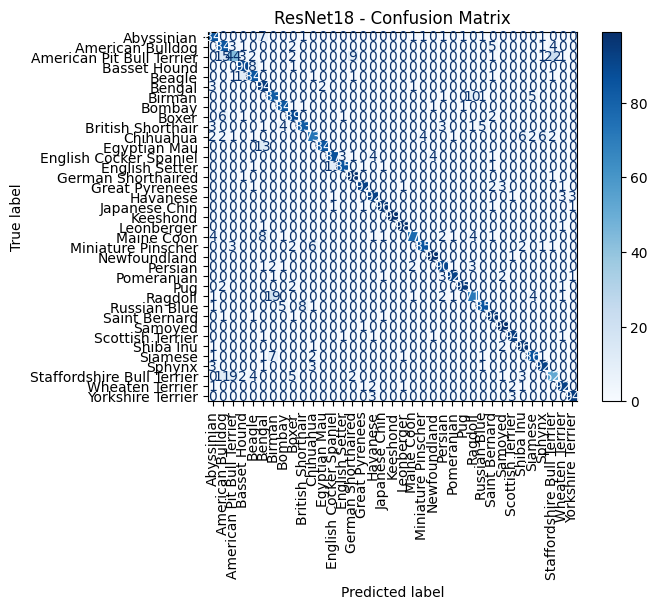

In [144]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(true_seed2026, pred_seed2026)

class_names = test_dataset.classes

plt.figure(figsize=(18, 18))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(
    xticks_rotation=90,
    cmap="Blues",
    values_format="d"
)
plt.title("ResNet18 - Confusion Matrix")
plt.show()

In [145]:
import pandas as pd
import numpy as np

class_errors = []

for i, name in enumerate(class_names):
    total = cm[i].sum()
    correct = cm[i, i]
    error = total - correct
    error_rate = error / total

    class_errors.append({
        "Class": name,
        "Correct": correct,
        "Errors": error,
        "Error rate": error_rate
    })

error_df = pd.DataFrame(class_errors)
error_df = error_df.sort_values("Errors", ascending=False)

display(error_df.head(10))

,Class,Correct,Errors,Error rate
2,American Pit Bull Terrier,44,56,0.56000
34,Staffordshire Bull Terrier,52,37,0.41573
26,Ragdoll,71,29,0.29000
10,Chihuahua,73,27,0.27000
20,Maine Coon,77,23,0.23000
9,British Shorthair,83,17,0.17000
6,Birman,83,17,0.17000
1,American Bulldog,84,16,0.16000
4,Beagle,84,16,0.16000
21,Miniature Pinscher,85,15,0.15000


In [146]:
from sklearn.metrics import classification_report

report = classification_report(
    true_seed2026,
    pred_seed2026,
    target_names=class_names,
    digits=4
)

print(report)

                            precision    recall  f1-score   support

                Abyssinian     0.8077    0.8571    0.8317        98
          American Bulldog     0.6942    0.8400    0.7602       100
 American Pit Bull Terrier     0.7213    0.4400    0.5466       100
              Basset Hound     0.8257    0.9000    0.8612       100
                    Beagle     0.8235    0.8400    0.8317       100
                    Bengal     0.7287    0.9400    0.8210       100
                    Birman     0.7411    0.8300    0.7830       100
                    Bombay     0.8842    0.9545    0.9180        88
                     Boxer     0.8476    0.8990    0.8725        99
         British Shorthair     0.8925    0.8300    0.8601       100
                 Chihuahua     0.8391    0.7300    0.7807       100
              Egyptian Mau     0.9767    0.8660    0.9180        97
    English Cocker Spaniel     0.8700    0.8700    0.8700       100
            English Setter     0.9444    0.8500

In [147]:
confusions = []

for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            confusions.append({
                "True class": class_names[i],
                "Predicted as": class_names[j],
                "Count": cm[i, j]
            })

confusion_df = pd.DataFrame(confusions)
confusion_df = confusion_df.sort_values(
    "Count", ascending=False
)

display(confusion_df.head(10))

,True class,Predicted as,Count
21,American Pit Bull Terrier,Staffordshire Bull Terrier,22
122,Ragdoll,Birman,19
14,American Pit Bull Terrier,American Bulldog,15
63,Egyptian Mau,Bengal,13
70,English Setter,English Cocker Spaniel,11
156,Staffordshire Bull Terrier,American Bulldog,11
27,Beagle,Basset Hound,11
36,Birman,Ragdoll,10
18,American Pit Bull Terrier,German Shorthaired,9
157,Staffordshire Bull Terrier,American Pit Bull Terrier,9


In [148]:
results = pd.DataFrame({
    "Experiment": [
        "AnimalCNN",
        "ResNet18 - LR 0.0001",
        "ResNet18 - LR 0.001",
        "ResNet18 - No Augmentation"
    ],
    "Test Accuracy (%)": [
        8.34, 87.00, None, 88.20
    ],
    "Macro F1 (%)": [
        6.45, 86.86, None, 87.98
    ]
})

display(results)

,Experiment,Test Accuracy (%),Macro F1 (%)
0,AnimalCNN,8.34,6.45
1,ResNet18 - LR 0.0001,87.00,86.86
2,ResNet18 - LR 0.001,NaN,NaN
3,ResNet18 - No Augmentation,88.20,87.98


In [149]:
model_lr001 = models.resnet18(weights=None)
model_lr001.fc = nn.Linear(model_lr001.fc.in_features, 37)

model_lr001.load_state_dict(
    torch.load(
        "/kaggle/working/ResNet18_LR001.pth",
        map_location=device,
        weights_only=True
    )
)

model_lr001 = model_lr001.to(device)
model_lr001.eval()

pred_lr001 = []
true_lr001 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_lr001(images)
        predictions = outputs.argmax(1)

        pred_lr001.extend(predictions.cpu().numpy())
        true_lr001.extend(labels.numpy())

acc_lr001 = accuracy_score(true_lr001, pred_lr001)
f1_lr001 = f1_score(true_lr001, pred_lr001, average="macro")

print(f"LR 0.001 Test Accuracy: {acc_lr001:.4f}")
print(f"LR 0.001 Test Macro F1: {f1_lr001:.4f}")

LR 0.001 Test Accuracy: 0.6171
LR 0.001 Test Macro F1: 0.6190


In [150]:
results = pd.DataFrame({
    "Experiment": [
        "AnimalCNN",
        "ResNet18 - LR 0.0001",
        "ResNet18 - LR 0.001",
        "ResNet18 - No Augmentation"
    ],
    "Test Accuracy (%)": [8.34, 87.00, 61.71, 88.20],
    "Macro F1 (%)": [6.45, 86.86, 61.90, 87.98]
})

display(results)

,Experiment,Test Accuracy (%),Macro F1 (%)
0,AnimalCNN,8.34,6.45
1,ResNet18 - LR 0.0001,87.00,86.86
2,ResNet18 - LR 0.001,61.71,61.90
3,ResNet18 - No Augmentation,88.20,87.98


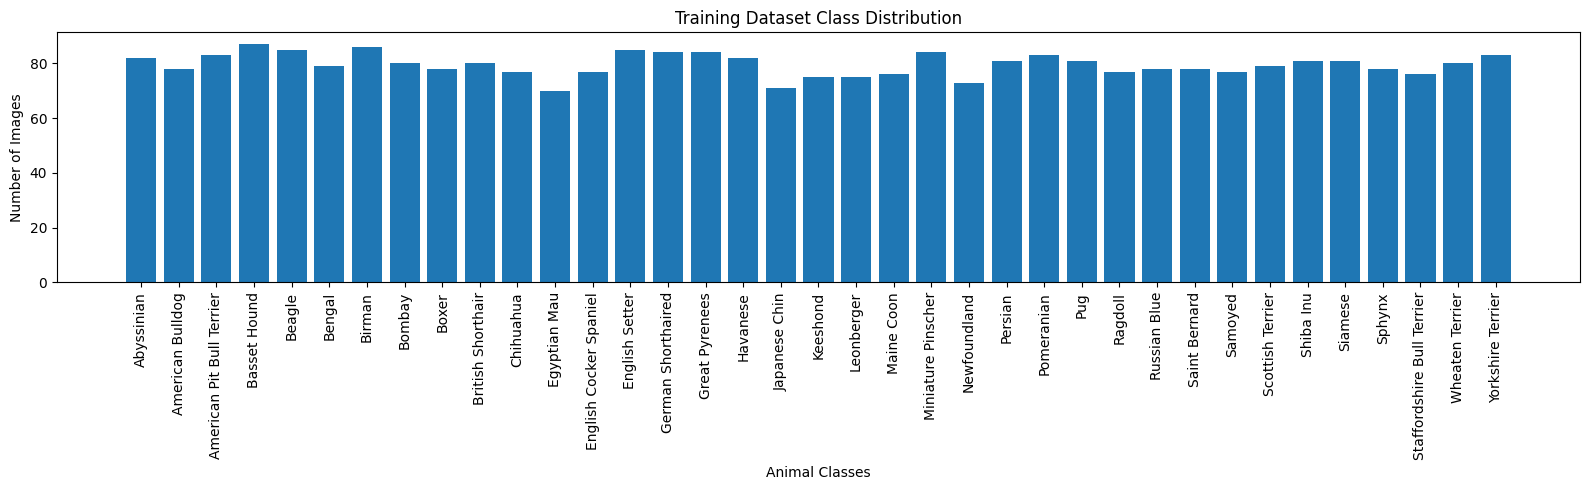

Number of classes: 37
Minimum images per class: 70
Maximum images per class: 87


In [151]:
from collections import Counter
import matplotlib.pyplot as plt

class_counts = Counter()

for _, labels in train_loader:
    class_counts.update(labels.numpy().tolist())

counts = [class_counts[i] for i in range(37)]

plt.figure(figsize=(16, 5))
plt.bar(class_names, counts)
plt.xticks(rotation=90)
plt.xlabel("Animal Classes")
plt.ylabel("Number of Images")
plt.title("Training Dataset Class Distribution")
plt.tight_layout()
plt.show()

print("Number of classes:", len(counts))
print("Minimum images per class:", min(counts))
print("Maximum images per class:", max(counts))

In [152]:
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score

train_labels = [label for _, label in train_dataset]
majority_class = Counter(train_labels).most_common(1)[0][0]

baseline_preds = [majority_class] * len(test_dataset)
test_labels = [label for _, label in test_dataset]

baseline_acc = accuracy_score(test_labels, baseline_preds)
baseline_f1 = f1_score(
    test_labels,
    baseline_preds,
    average="macro",
    zero_division=0
)

print("Majority class:", class_names[majority_class])
print(f"Baseline Accuracy: {baseline_acc:.4f}")
print(f"Baseline Macro F1: {baseline_f1:.4f}")

Majority class: Basset Hound
Baseline Accuracy: 0.0273
Baseline Macro F1: 0.0014


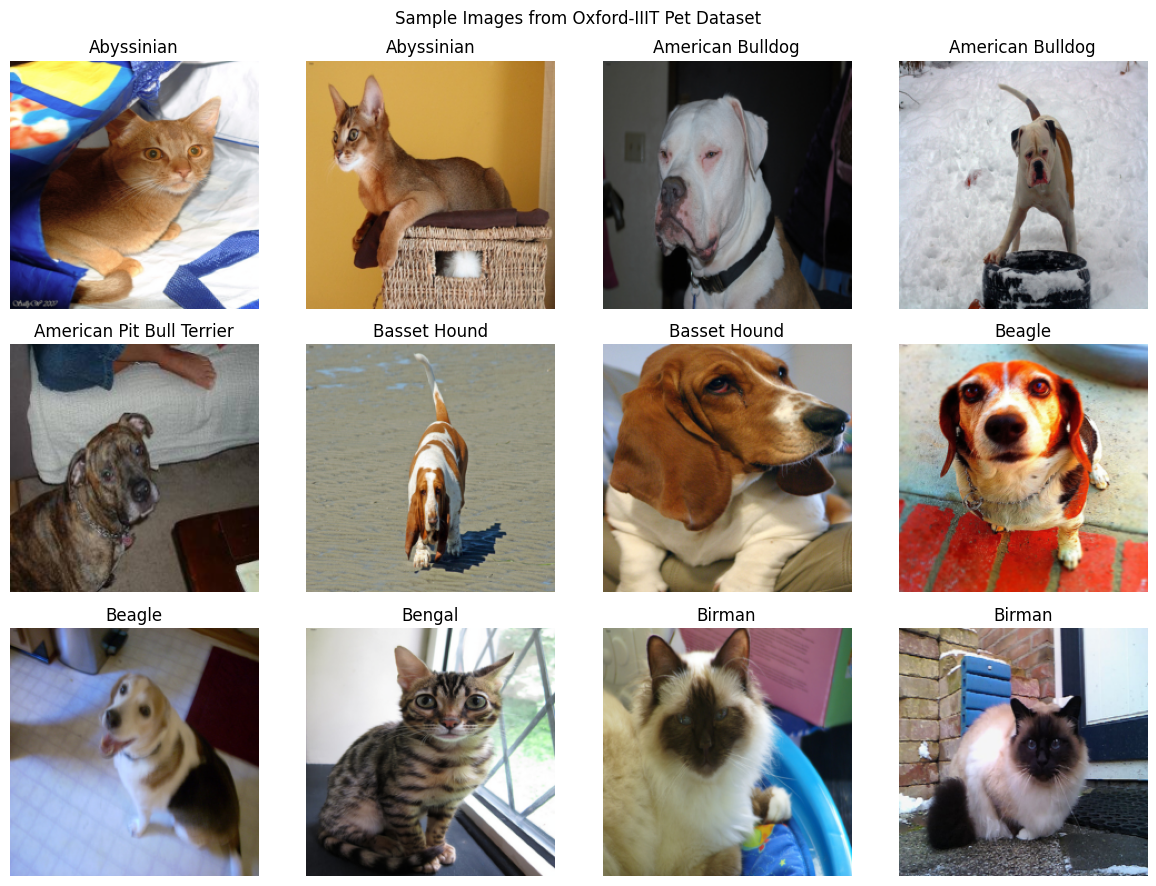

In [153]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    image, label = train_eval[i * 30]

    image = image.permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = np.clip(image * std + mean, 0, 1)

    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle("Sample Images from Oxford-IIIT Pet Dataset")
plt.tight_layout()
plt.show()

In [155]:
import numpy as np

accs = np.array([
    acc_seed42,
    acc_seed123,
    acc_seed2026
])

f1s = np.array([
    f1_seed42,
    f1_seed123,
    f1_seed2026
])

print("Accuracy:", accs.mean(), "±", accs.std(ddof=1))
print("Macro F1:", f1s.mean(), "±", f1s.std(ddof=1))

Accuracy: 0.8736258744435359 ± 0.004234098372937642
Macro F1: 0.8711321399106727 ± 0.004307963892025054


In [156]:
import json

final_results = {
    "dataset": "Oxford-IIIT Pet",
    "classes": 37,
    "train_images": 2944,
    "validation_images": 736,
    "test_images": 3669,
    "baseline_accuracy": baseline_acc,
    "baseline_macro_f1": baseline_f1,
    "animal_cnn_accuracy": 0.0834,
    "animal_cnn_macro_f1": 0.0645,
    "resnet18_accuracy": 0.8700,
    "resnet18_macro_f1": 0.8686,
    "no_augmentation_accuracy": 0.8820,
    "no_augmentation_macro_f1": 0.8798,
    "seed_mean_accuracy": float(accs.mean()),
    "seed_std_accuracy": float(accs.std(ddof=1)),
    "seed_mean_macro_f1": float(f1s.mean()),
    "seed_std_macro_f1": float(f1s.std(ddof=1))
}

with open("/kaggle/working/final_results.json", "w") as f:
    json.dump(final_results, f, indent=4)

print("Final results saved!")

Final results saved!


In [157]:
import os
import zipfile

files_to_save = [
    "final_results.json",
    "ModelA_results.json",
    "ModelB_results.json",
    "Experiment1_LR001.json",
    "Experiment2_NoAug.json",
    "AnimalCNN_model.pth",
    "ResNet18_model.pth",
    "ResNet18_LR001.pth",
    "ResNet18_NoAug.pth"
]

zip_path = "/kaggle/working/Animal_Classification_Project.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for filename in files_to_save:
        path = f"/kaggle/working/{filename}"
        if os.path.exists(path):
            zipf.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("Not found:", filename)

print("\nZIP file created!")
print("Location:", zip_path)

Added: final_results.json
Added: ModelA_results.json
Added: ModelB_results.json
Added: Experiment1_LR001.json
Added: Experiment2_NoAug.json
Added: AnimalCNN_model.pth
Added: ResNet18_model.pth
Added: ResNet18_LR001.pth
Added: ResNet18_NoAug.pth

ZIP file created!
Location: /kaggle/working/Animal_Classification_Project.zip
